# Sample-wise Conditional Fusion — Amazon Reviews 2023 (Appliances)

This notebook builds the full experiment pipeline for assessing **sample-wise conditional
fusion** on a subset of the Amazon Reviews 2023 dataset (Appliances category).

Pipeline:
1. Setup & config
2. Data extraction (decompress, DuckDB subset query)
3. Label engineering (binary: rating 1-3 = negative, 4-5 = positive)
4. Image encoding (DINOv2, 768-dim, first image per sample)
5. Text encoding (BGE v1.5 base, 768-dim, **title** and **text** encoded separately)
6. Feature assembly & stratified train/val/test split
7. Fusion models — three independent methods (**mean**, **concat**, **cross-attention**),
   each with a branch projection to a common dim and a post-fusion projection to a
   shared output dim
8. Training — one model per fusion method, identical shared MLP head
9. Evaluation — global comparison of the three fusion methods

## 1. Setup

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
from pathlib import Path

HOME_DIR = Path("/content/drive/MyDrive/Magister/DataMining")

In [ ]:
# duckdb for subset queries; sentence-transformers for BGE v1.5.
!pip install duckdb sentence-transformers --quiet

### Imports

All imports are centralised here. Core libraries: DuckDB (querying the raw JSONL),
PyTorch + Transformers (DINOv2), Sentence-Transformers (BGE v1.5), scikit-learn
(splits and metrics).

In [ ]:
import ast
import gzip
import os
import random
import shutil
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
from PIL import Image
from sentence_transformers import SentenceTransformer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel

### Config, seeding & device

`D_BRANCH` is the common dimension every modality branch is projected to *before*
fusion (this makes mean/cross-attention dimensionally valid and keeps the three
fusion methods comparable). `D_FUSION` is the shared output dimension every fusion
method is projected to *after* fusion, feeding the shared MLP head.

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_ROWS = 1000

IMAGE_URL_FIELD = "small_image_url"   # "small_image_url" | "large_image_url"
TEXT_MODEL_NAME = "BAAI/bge-base-en-v1.5"

IMG_DIM = 768                         # DINOv2-base CLS dim
TEXT_DIM = 768                        # BGE base v1.5 dim

D_BRANCH = 512                        # per-branch pre-fusion projection dim
D_FUSION = 512                        # post-fusion projection dim (shared output)
HIDDEN = 256                          # MLP hidden dim

BATCH_SIZE = 128
EPOCHS = 300
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 300

FUSION_METHODS = ["mean", "concat", "cross_attn"]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


## 2. Data extraction — Amazon Reviews 2023 (Appliances)

In [ ]:
review_compressed = HOME_DIR / "Dataset" / "amazon_review_2023" / "Appliances.jsonl.gz"
review_json = HOME_DIR / "Dataset" / "amazon_review_2023" / "Appliances.jsonl"

meta_review_compressed = HOME_DIR / "Dataset" / "amazon_review_2023" / "meta_Appliances.jsonl.gz"
meta_review_json = HOME_DIR / "Dataset" / "amazon_review_2023" / "meta_Appliances.jsonl"

subset_file = HOME_DIR / "Dataset" / "amazon_review_2023" / "appliances.csv"

image_emb_file = HOME_DIR / "Dataset" / "amazon_review_2023" / "appliances_image_emb.npy"
title_emb_file = HOME_DIR / "Dataset" / "amazon_review_2023" / "appliances_title_emb.npy"
text_emb_file = HOME_DIR / "Dataset" / "amazon_review_2023" / "appliances_text_emb.npy"
metrics_file = HOME_DIR / "Dataset" / "amazon_review_2023" / "appliances_fusion_metrics.csv"

### Decompress the `.gz` files

In [ ]:
def decompress(src, dst):
    if os.path.exists(dst):
        print(f"Skipping extraction. Already exists: {dst}")
        return
    print(f"Extracting {src}")
    with gzip.open(src, "rb") as f_in, open(dst, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)
    print(f"Extracted to {dst}")


decompress(review_compressed, review_json)
decompress(meta_review_compressed, meta_review_json)

Skipping extraction. Already exists: /content/drive/MyDrive/Magister/DataMining/Dataset/amazon_review_2023/Appliances.jsonl
Skipping extraction. Already exists: /content/drive/MyDrive/Magister/DataMining/Dataset/amazon_review_2023/meta_Appliances.jsonl


### Query the subset with DuckDB

Rating distribution in the full review file:

In [ ]:
import duckdb

conn = duckdb.connect()

distribution_query = f"""
WITH TotalCount AS (
    SELECT COUNT(*) AS total FROM read_json_auto('{review_json}')
)
SELECT
    rating,
    COUNT(*) AS rating_count,
    ROUND(COUNT(*) * 100.0 / (SELECT total FROM TotalCount), 2) AS percentage
FROM read_json_auto('{review_json}')
GROUP BY rating
ORDER BY rating DESC;
"""

df_dist = conn.execute(distribution_query).df()
print(df_dist)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   rating  rating_count  percentage
0     5.0       1486225       69.82
1     4.0        208216        9.78
2     3.0        104047        4.89
3     2.0         79664        3.74
4     1.0        250453       11.77


### Allocate per-rating subset counts

In [ ]:
df_dist["subset_count"] = round(df_dist["percentage"] * MAX_ROWS / 100).astype(int)
df_dist

,rating,rating_count,percentage,subset_count
0,5.0,1486225,69.82,698
1,4.0,208216,9.78,98
2,3.0,104047,4.89,49
3,2.0,79664,3.74,37
4,1.0,250453,11.77,118


Draw a stratified subset from reviews that have at least one image. The subset is
sampled per rating so the original rating distribution is preserved.

In [ ]:
data_list = []
for i in range(5):
    n = df_dist.loc[df_dist["rating"] == float(i + 1), "subset_count"].values[0]
    query = f"""
    SELECT
        rating,
        title,
        text,
        parent_asin,
        user_id,
        images,
        to_timestamp(cast(timestamp / 1000 as BIGINT)) AS review_time
    FROM read_json_auto('{review_json}')
    WHERE rating = {float(i + 1)}
      AND images IS NOT NULL
      AND len(images) > 0
    LIMIT {n};
    """
    data_list += conn.execute(query).df().to_dict(orient="records")

subset = pd.DataFrame(data_list)
subset.to_csv(subset_file)
print("Subset shape:", subset.shape)

Subset shape: (1000, 7)


## 3. Label engineering

Reload from CSV (so the rest of the notebook can run independently) and add the
binary label: **rating 1-3 -> 0 (negative)**, **rating 4-5 -> 1 (positive)**.

In [ ]:
subset = pd.read_csv(subset_file, index_col=0)
subset["label"] = (subset["rating"] >= 4).astype(int)

print("Rating counts:")
print(subset["rating"].value_counts().sort_index())
print("\nClass balance:")
print(subset["label"].value_counts())

Rating counts:
rating
1.0    118
2.0     37
3.0     49
4.0     98
5.0    698
Name: count, dtype: int64

Class balance:
label
1    796
0    204
Name: count, dtype: int64


## 4. Image encoding — DINOv2

In [ ]:
img_model_name = "facebook/dinov2-base"  # 768-dimensional CLS output
img_processor = AutoImageProcessor.from_pretrained(img_model_name)
img_model = AutoModel.from_pretrained(img_model_name).to(DEVICE)
img_model.eval()

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Dinov2Model(
  (embeddings): Dinov2Embeddings(
    (patch_embeddings): Dinov2PatchEmbeddings(
      (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): Dinov2Encoder(
    (layer): ModuleList(
      (0-11): 12 x Dinov2Layer(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attention): Dinov2Attention(
          (q_proj): Linear(in_features=768, out_features=768, bias=True)
          (k_proj): Linear(in_features=768, out_features=768, bias=True)
          (v_proj): Linear(in_features=768, out_features=768, bias=True)
          (o_proj): Linear(in_features=768, out_features=768, bias=True)
        )
        (layer_scale1): Dinov2LayerScale()
        (drop_path): Identity()
        (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): Dinov2MLP(
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=768, out_features=3072, bias=

In [ ]:
def get_image_embedding(image_url):
    """Download a single image and return its DINOv2 CLS vector, or None."""
    try:
        response = requests.get(image_url, timeout=10)
        if response.status_code != 200:
            return None
        img = Image.open(BytesIO(response.content)).convert("RGB")
        inputs = img_processor(images=img, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            outputs = img_model(**inputs)
            emb = outputs.last_hidden_state[:, 0, :].cpu().squeeze(0).numpy()
        return emb
    except Exception:
        return None

Parse the first image URL per sample. `images` is stored as a Python-literal string
after the CSV round-trip, so it is parsed defensively.

In [ ]:
def first_image_url(images):
    if isinstance(images, str):
        try:
            images = ast.literal_eval(images)
        except Exception:
            return None
    if isinstance(images, list) and len(images) > 0:
        first = images[0]
        if isinstance(first, dict):
            return first.get(IMAGE_URL_FIELD)
    return None


subset["first_image"] = subset["images"].apply(first_image_url)
print(subset[["rating", "first_image"]].head())

   rating                                        first_image
0     1.0  https://m.media-amazon.com/images/I/61xDBuHT1R...
1     1.0  https://m.media-amazon.com/images/I/61uY9Rz+gA...
2     1.0  https://m.media-amazon.com/images/I/7133XhA0AD...
3     1.0  https://images-na.ssl-images-amazon.com/images...
4     1.0  https://m.media-amazon.com/images/I/71OjenULYp...


Encode the first image of every sample. Failures / missing images are stored as
`NaN` rows and filtered out later.

In [ ]:
image_embeddings = np.full((len(subset), IMG_DIM), np.nan, dtype=np.float32)

for i, url in enumerate(tqdm(subset["first_image"].tolist(), desc="Encoding images")):
    if isinstance(url, str) and url:
        emb = get_image_embedding(url)
        if emb is not None:
            image_embeddings[i] = emb

np.save(image_emb_file, image_embeddings)
encoded = int(np.isfinite(image_embeddings).all(axis=1).sum())
print(f"Encoded images: {encoded} / {len(subset)}")

Encoding images:   0%|          | 0/1000 [00:00<?, ?it/s]

Encoded images: 484 / 1000


## 5. Text encoding — BGE v1.5 (base)

Both the **title** and the **text** columns are encoded independently with
`BAAI/bge-base-en-v1.5` (768-dim). They remain two separate fusion branches
(image + title + text), rather than being merged into a single text vector.

In [ ]:
text_model = SentenceTransformer(
    TEXT_MODEL_NAME,
    device=str(DEVICE),
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
def encode_texts(texts):
    texts = [t if isinstance(t, str) and t.strip() else "" for t in texts]
    return text_model.encode(
        texts,
        batch_size=64,
        normalize_embeddings=True,
        show_progress_bar=True,
    )


title_embeddings = encode_texts(subset["title"].tolist())
text_embeddings = encode_texts(subset["text"].tolist())

np.save(title_emb_file, title_embeddings)
np.save(text_emb_file, text_embeddings)

print("Title embeddings:", title_embeddings.shape)
print("Text embeddings: ", text_embeddings.shape)

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Title embeddings: (1000, 768)
Text embeddings:  (1000, 768)


## 6. Feature assembly & split

In [ ]:
image_embeddings = np.load(image_emb_file)
title_embeddings = np.load(title_emb_file)
text_embeddings = np.load(text_emb_file)

valid = (
    np.isfinite(image_embeddings).all(axis=1)
    & np.isfinite(title_embeddings).all(axis=1)
    & np.isfinite(text_embeddings).all(axis=1)
)

X_img = image_embeddings[valid]
X_title = title_embeddings[valid]
X_text = text_embeddings[valid]
y = subset["label"].to_numpy()[valid]

print(f"Valid samples: {valid.sum()} / {len(valid)}")
print("X_img:", X_img.shape, "X_title:", X_title.shape, "X_text:", X_text.shape, "y:", y.shape)

Valid samples: 484 / 1000
X_img: (484, 768) X_title: (484, 768) X_text: (484, 768) y: (484,)


Stratified split: 64% train, 16% validation, 20% test.

In [ ]:
idx = np.arange(len(y))

idx_train, idx_test, y_train, y_test = train_test_split(
    idx, y, test_size=0.2, random_state=SEED, stratify=y
)
idx_train, idx_val, y_train, y_val = train_test_split(
    idx_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

print("Train:", len(idx_train), "Val:", len(idx_val), "Test:", len(idx_test))

Train: 309 Val: 78 Test: 97


## 7. Fusion models

Architecture, shared across all three methods:

- **Branch projections**: image `768 -> D_BRANCH`, title `768 -> D_BRANCH`,
  text `768 -> D_BRANCH`.
- **Fusion** (the only variable between models):
  - `mean` — element-wise mean of the three projected branch vectors.
  - `concat` — concatenate the three projected branch vectors.
  - `cross_attn` — image vector is the **query**, title & text vectors are the
    **keys/values**; the pooled attention output is used.
- **Post-fusion projection**: every fusion output is projected to `D_FUSION`.
- **Shared MLP head**: `D_FUSION -> HIDDEN -> 2` (identical for all methods).

In [ ]:
class BranchProjection(nn.Module):
    """Project one modality branch to the common per-branch dimension."""

    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )

    def forward(self, x):
        return self.proj(x)


class MeanFusion(nn.Module):
    def __init__(self, d_branch, d_fusion):
        super().__init__()
        self.post = nn.Sequential(
            nn.Linear(d_branch, d_fusion),
            nn.LayerNorm(d_fusion),
            nn.GELU(),
        )

    def forward(self, branches):
        fused = torch.stack(branches, dim=0).mean(dim=0)
        return self.post(fused)


class ConcatFusion(nn.Module):
    def __init__(self, d_branch, d_fusion, n_branches=3):
        super().__init__()
        self.post = nn.Sequential(
            nn.Linear(d_branch * n_branches, d_fusion),
            nn.LayerNorm(d_fusion),
            nn.GELU(),
        )

    def forward(self, branches):
        fused = torch.cat(branches, dim=-1)
        return self.post(fused)


class CrossAttentionFusion(nn.Module):
    """Image (query) cross-attends to title + text (key/value)."""

    def __init__(self, d_branch, d_fusion, n_heads=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_branch, n_heads, batch_first=True)
        self.norm = nn.LayerNorm(d_branch)
        self.post = nn.Sequential(
            nn.Linear(d_branch, d_fusion),
            nn.LayerNorm(d_fusion),
            nn.GELU(),
        )

    def forward(self, branches):
        img, title, text = branches
        query = img.unsqueeze(1)                       # (N, 1, d)
        kv = torch.stack([title, text], dim=1)         # (N, 2, d)
        out, _ = self.attn(query, kv, kv, need_weights=False)
        return self.post(self.norm(out.squeeze(1)))


class FusionClassifier(nn.Module):
    def __init__(self, method, img_dim, title_dim, text_dim, d_branch, d_fusion, hidden):
        super().__init__()
        self.method = method
        self.p_img = BranchProjection(img_dim, d_branch)
        self.p_title = BranchProjection(title_dim, d_branch)
        self.p_text = BranchProjection(text_dim, d_branch)

        if method == "mean":
            self.fusion = MeanFusion(d_branch, d_fusion)
        elif method == "concat":
            self.fusion = ConcatFusion(d_branch, d_fusion)
        elif method == "cross_attn":
            self.fusion = CrossAttentionFusion(d_branch, d_fusion)
        else:
            raise ValueError(f"Unknown fusion method: {method}")

        self.head = nn.Sequential(
            nn.Linear(d_fusion, hidden),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, 2),
        )

    def forward(self, img, title, text):
        branches = (self.p_img(img), self.p_title(title), self.p_text(text))
        return self.head(self.fusion(branches))

## 8. Training

In [ ]:
class MultiModalDataset(Dataset):
    def __init__(self, img, title, text, y):
        self.img = torch.as_tensor(img, dtype=torch.float32)
        self.title = torch.as_tensor(title, dtype=torch.float32)
        self.text = torch.as_tensor(text, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.img[i], self.title[i], self.text[i], self.y[i]

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0.0
    for img, title, text, y in loader:
        img, title, text, y = img.to(DEVICE), title.to(DEVICE), text.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        logits = model(img, title, text)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    logits_all, y_all = [], []
    for img, title, text, y in loader:
        img, title, text = img.to(DEVICE), title.to(DEVICE), text.to(DEVICE)
        logits_all.append(model(img, title, text).cpu())
        y_all.append(y)

    logits = torch.cat(logits_all)
    y_true = torch.cat(y_all).numpy()
    loss = criterion(logits, torch.cat(y_all)).item()
    preds = logits.argmax(dim=1).numpy()
    probs = torch.softmax(logits, dim=1).numpy()[:, 1]
    return y_true, preds, probs, loss

One model per fusion method. Everything except the fusion module (branch
projections, shared head, optimizer, seed, epochs) is held constant so the fusion
method is the only variable being compared.

In [ ]:
def run_experiment(method):
    torch.manual_seed(SEED)

    model = FusionClassifier(
        method, IMG_DIM, TEXT_DIM, TEXT_DIM, D_BRANCH, D_FUSION, HIDDEN
    ).to(DEVICE)

    train_ds = MultiModalDataset(X_img[idx_train], X_title[idx_train], X_text[idx_train], y_train)
    val_ds = MultiModalDataset(X_img[idx_val], X_title[idx_val], X_text[idx_val], y_val)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    best_val = float("inf")
    best_state = None
    wait = 0

    for epoch in range(EPOCHS):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        _, _, _, val_loss = evaluate(model, val_loader, criterion)
        print(f"[{method}] epoch {epoch + 1:02d} | train {train_loss:.4f} | val {val_loss:.4f}")

        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"[{method}] early stopping")
                break

    model.load_state_dict(best_state)
    return model, best_val

In [ ]:
models = {}
val_losses = {}

for method in FUSION_METHODS:
    print("=" * 60)
    print("Fusion:", method)
    model, best_val = run_experiment(method)
    models[method] = model
    val_losses[method] = best_val
    torch.save(model.state_dict(), HOME_DIR / "Dataset" / "amazon_review_2023" / f"fusion_{method}.pt")

Fusion: mean
[mean] epoch 01 | train 0.5638 | val 0.4349
[mean] epoch 02 | train 0.3861 | val 0.2139
[mean] epoch 03 | train 0.1579 | val 0.0773
[mean] epoch 04 | train 0.0658 | val 0.0634
[mean] epoch 05 | train 0.0193 | val 0.1057
[mean] epoch 06 | train 0.0019 | val 0.1593
[mean] epoch 07 | train 0.0014 | val 0.2300
[mean] epoch 08 | train 0.0006 | val 0.3341
[mean] epoch 09 | train 0.0002 | val 0.4086
[mean] epoch 10 | train 0.0002 | val 0.4623
[mean] epoch 11 | train 0.0001 | val 0.4988
[mean] epoch 12 | train 0.0001 | val 0.5249
[mean] epoch 13 | train 0.0000 | val 0.5440
[mean] epoch 14 | train 0.0000 | val 0.5580
[mean] epoch 15 | train 0.0000 | val 0.5689
[mean] epoch 16 | train 0.0000 | val 0.5773
[mean] epoch 17 | train 0.0000 | val 0.5842
[mean] epoch 18 | train 0.0000 | val 0.5901
[mean] epoch 19 | train 0.0000 | val 0.5955
[mean] epoch 20 | train 0.0000 | val 0.6000
[mean] epoch 21 | train 0.0000 | val 0.6036
[mean] epoch 22 | train 0.0000 | val 0.6065
[mean] epoch 23 | t

## 9. Evaluation & comparison

Evaluate all three trained models on the held-out test set and compare them
globally. This is the first step toward the research goal: which fusion method is
more suitable. Per-sample analysis is a follow-up.

In [ ]:
criterion = nn.CrossEntropyLoss()
rows = []

for method, model in models.items():
    test_ds = MultiModalDataset(X_img[idx_test], X_title[idx_test], X_text[idx_test], y_test)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

    y_true, y_pred, y_prob, _ = evaluate(model, test_loader, criterion)

    rows.append({
        "method": method,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    })

    print(f"\n[{method}] confusion matrix:")
    print(confusion_matrix(y_true, y_pred))

results = pd.DataFrame(rows).set_index("method").sort_values("f1", ascending=False)
print("\n=== Fusion method comparison (test set) ===")
print(results.round(4))

results.to_csv(metrics_file)
print("\nSaved metrics to:", metrics_file)


[mean] confusion matrix:
[[17  3]
 [ 3 74]]

[concat] confusion matrix:
[[17  3]
 [ 3 74]]

[cross_attn] confusion matrix:
[[19  1]
 [ 4 73]]

=== Fusion method comparison (test set) ===
            accuracy  precision  recall      f1  roc_auc
method                                                  
cross_attn    0.9485     0.9865  0.9481  0.9669   0.9916
mean          0.9381     0.9610  0.9610  0.9610   0.9753
concat        0.9381     0.9610  0.9610  0.9610   0.9831

Saved metrics to: /content/drive/MyDrive/Magister/DataMining/Dataset/amazon_review_2023/appliances_fusion_metrics.csv


### Notes & caveats

- **Cross-attention is weak with single-vector branches.** The image branch provides
  only one query token and the text branches only two key/value tokens, so the
  attention reduces to a learned gated sum. A stronger variant would use DINOv2
  **patch tokens** as queries. This can be added later without changing the overall
  pipeline.
- **Fair comparison**: branch projections, shared MLP head, optimizer, seed, and
  early-stopping are identical across methods; only the fusion module differs.
- **Per-sample assessment** ("which fusion method suits which samples") is the next
  step. This notebook establishes the global baseline. A natural extension is to
  compute per-sample correctness per method and analyse where they disagree.
- **Encoder swap (BGE v1.5).** The text encoder is `BAAI/bge-base-en-v1.5`
  (768-dim), replacing Jina v3. Cached `appliances_title_emb.npy` /
  `appliances_text_emb.npy` (1024-dim) and the previously trained `fusion_*.pt`
  checkpoints are therefore **invalid** and must be regenerated by re-running
  Sections 5-8.


## 10. Per-sample fusion assessment

Section 9 compared the three fusion methods **globally**. Here we go a step further and
decide, **for every test sample, which fusion method performs best**, then analyse those
verdicts conditionally (by rating and by text/title length) and aggregate the win rates.

**Winner rule** (correctness + confidence):

1. Keep only methods that predicted the sample's true label.
2. Among those, the winner is the one with the highest probability for the true class.
3. Ties are broken deterministically in the order `mean -> concat -> cross_attn`.
4. If **no** method is correct, the sample is labelled `all_wrong`.

A secondary signal `best_loss_method` (lowest per-sample NLL) is always recorded, even for
`all_wrong` samples.

This section is **fully standalone**: it rebuilds the config, model definitions, embeddings,
split and sample metadata, then loads the checkpoints saved by Section 8. It can therefore
be run on its own (after Sections 7-8 have produced the `.pt` files).


### 10.1 Standalone bootstrap

In [ ]:
# ============================================================
# Section 10 - standalone bootstrap
# Rebuilds config, model definitions, embeddings, split and
# sample metadata so this section can run on its own.
# ============================================================
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

SEED = 42
IMG_DIM = 768
TEXT_DIM = 768
D_BRANCH = 512
D_FUSION = 512
HIDDEN = 256
BATCH_SIZE = 128
FUSION_METHODS = ["mean", "concat", "cross_attn"]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HOME_DIR = Path("/content/drive/MyDrive/Magister/DataMining")
DATA_DIR = HOME_DIR / "Dataset" / "amazon_review_2023"

subset_file = DATA_DIR / "appliances.csv"
image_emb_file = DATA_DIR / "appliances_image_emb.npy"
title_emb_file = DATA_DIR / "appliances_title_emb.npy"
text_emb_file = DATA_DIR / "appliances_text_emb.npy"

persample_file = DATA_DIR / "appliances_fusion_persample.csv"
persample_summary_file = DATA_DIR / "appliances_fusion_persample_summary.csv"


# ---- Model definitions (identical to Sections 7-8) ----
class BranchProjection(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU(),
        )

    def forward(self, x):
        return self.proj(x)


class MeanFusion(nn.Module):
    def __init__(self, d_branch, d_fusion):
        super().__init__()
        self.post = nn.Sequential(
            nn.Linear(d_branch, d_fusion),
            nn.LayerNorm(d_fusion),
            nn.GELU(),
        )

    def forward(self, branches):
        fused = torch.stack(branches, dim=0).mean(dim=0)
        return self.post(fused)


class ConcatFusion(nn.Module):
    def __init__(self, d_branch, d_fusion, n_branches=3):
        super().__init__()
        self.post = nn.Sequential(
            nn.Linear(d_branch * n_branches, d_fusion),
            nn.LayerNorm(d_fusion),
            nn.GELU(),
        )

    def forward(self, branches):
        fused = torch.cat(branches, dim=-1)
        return self.post(fused)


class CrossAttentionFusion(nn.Module):
    def __init__(self, d_branch, d_fusion, n_heads=4):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_branch, n_heads, batch_first=True)
        self.norm = nn.LayerNorm(d_branch)
        self.post = nn.Sequential(
            nn.Linear(d_branch, d_fusion),
            nn.LayerNorm(d_fusion),
            nn.GELU(),
        )

    def forward(self, branches):
        img, title, text = branches
        query = img.unsqueeze(1)
        kv = torch.stack([title, text], dim=1)
        out, _ = self.attn(query, kv, kv, need_weights=False)
        return self.post(self.norm(out.squeeze(1)))


class FusionClassifier(nn.Module):
    def __init__(self, method, img_dim, title_dim, text_dim, d_branch, d_fusion, hidden):
        super().__init__()
        self.method = method
        self.p_img = BranchProjection(img_dim, d_branch)
        self.p_title = BranchProjection(title_dim, d_branch)
        self.p_text = BranchProjection(text_dim, d_branch)

        if method == "mean":
            self.fusion = MeanFusion(d_branch, d_fusion)
        elif method == "concat":
            self.fusion = ConcatFusion(d_branch, d_fusion)
        elif method == "cross_attn":
            self.fusion = CrossAttentionFusion(d_branch, d_fusion)
        else:
            raise ValueError(f"Unknown fusion method: {method}")

        self.head = nn.Sequential(
            nn.Linear(d_fusion, hidden),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, 2),
        )

    def forward(self, img, title, text):
        branches = (self.p_img(img), self.p_title(title), self.p_text(text))
        return self.head(self.fusion(branches))


class MultiModalDataset(Dataset):
    def __init__(self, img, title, text, y):
        self.img = torch.as_tensor(img, dtype=torch.float32)
        self.title = torch.as_tensor(title, dtype=torch.float32)
        self.text = torch.as_tensor(text, dtype=torch.float32)
        self.y = torch.as_tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.img[i], self.title[i], self.text[i], self.y[i]


# ---- Reload data, rebuild valid mask and the identical stratified split ----
subset = pd.read_csv(subset_file, index_col=0)
subset["label"] = (subset["rating"] >= 4).astype(int)

image_embeddings = np.load(image_emb_file)
title_embeddings = np.load(title_emb_file)
text_embeddings = np.load(text_emb_file)

valid = (
    np.isfinite(image_embeddings).all(axis=1)
    & np.isfinite(title_embeddings).all(axis=1)
    & np.isfinite(text_embeddings).all(axis=1)
)

X_img = image_embeddings[valid]
X_title = title_embeddings[valid]
X_text = text_embeddings[valid]
y = subset["label"].to_numpy()[valid]
subset_valid = subset[valid].reset_index(drop=True)

np.random.seed(SEED)
idx = np.arange(len(y))
idx_train, idx_test, y_train, y_test = train_test_split(
    idx, y, test_size=0.2, random_state=SEED, stratify=y
)
idx_train, idx_val, y_train, y_val = train_test_split(
    idx_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

# ---- Load the trained checkpoints from Section 8 ----
models = {}
missing = []
for method in FUSION_METHODS:
    ckpt = DATA_DIR / f"fusion_{method}.pt"
    if not ckpt.exists():
        missing.append(method)
        continue
    model = FusionClassifier(
        method, IMG_DIM, TEXT_DIM, TEXT_DIM, D_BRANCH, D_FUSION, HIDDEN
    ).to(DEVICE)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    model.eval()
    models[method] = model

if missing:
    raise FileNotFoundError(
        f"Missing checkpoints for {missing}. Run Sections 7-8 first to train and save them."
    )

print("Device:", DEVICE)
print(f"Valid samples: {valid.sum()} | Train {len(idx_train)} | Val {len(idx_val)} | Test {len(idx_test)}")
print("Loaded models:", list(models))


Device: cuda
Valid samples: 484 | Train 309 | Val 78 | Test 97
Loaded models: ['mean', 'concat', 'cross_attn']


### 10.2 Per-sample inference

In [ ]:
# ---- Per-sample inference on the held-out test set (order preserved) ----
test_ds = MultiModalDataset(X_img[idx_test], X_title[idx_test], X_text[idx_test], y_test)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

y_true = y_test.copy()
test_pos = np.arange(len(idx_test))

preds = {}
probs_true = {}
probs_all = {}

for method, model in models.items():
    p_list, prob_list = [], []
    with torch.no_grad():
        for img, title, text, _ in test_loader:
            img, title, text = img.to(DEVICE), title.to(DEVICE), text.to(DEVICE)
            logits = model(img, title, text)
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            p_list.append(probs.argmax(axis=1))
            prob_list.append(probs)
    probs_all[method] = np.concatenate(prob_list, axis=0)
    preds[method] = np.concatenate(p_list)
    probs_true[method] = probs_all[method][test_pos, y_true]

for method in FUSION_METHODS:
    acc = (preds[method] == y_true).mean()
    print(f"[{method}] test accuracy (recomputed): {acc:.4f}")


[mean] test accuracy (recomputed): 0.9381
[concat] test accuracy (recomputed): 0.9381
[cross_attn] test accuracy (recomputed): 0.9485


### 10.3 Per-sample verdict table

In [ ]:
# ---- Build the per-sample verdict table ----
def pick_winner(row):
    """Highest true-class probability among correct methods; ties by FUSION_METHODS order."""
    correct = [m for m in FUSION_METHODS if row[f"{m}_correct"]]
    if not correct:
        return "all_wrong"
    return max(correct, key=lambda m: (row[f"{m}_prob_true"], -FUSION_METHODS.index(m)))


df = pd.DataFrame({
    "test_pos": test_pos,
    "subset_idx": np.where(valid)[0][idx_test],
    "rating": subset_valid["rating"].to_numpy()[idx_test],
    "label": y_true,
    "text_len": subset_valid["text"].fillna("").astype(str).str.len().to_numpy()[idx_test],
    "title_len": subset_valid["title"].fillna("").astype(str).str.len().to_numpy()[idx_test],
})

for m in FUSION_METHODS:
    df[f"{m}_pred"] = preds[m]
    df[f"{m}_prob_true"] = probs_true[m]
    df[f"{m}_correct"] = preds[m] == y_true
    df[f"{m}_loss"] = -np.log(np.clip(probs_true[m], 1e-12, None))

df["winner"] = df.apply(pick_winner, axis=1)
df["best_loss_method"] = (
    df[[f"{m}_loss" for m in FUSION_METHODS]].idxmin(axis=1).str.replace("_loss", "", regex=False)
)

df.to_csv(persample_file, index=False)
print(f"Per-sample table: {df.shape} -> {persample_file}")
df.head(10)


Per-sample table: (97, 20) -> /content/drive/MyDrive/Magister/DataMining/Dataset/amazon_review_2023/appliances_fusion_persample.csv


,test_pos,subset_idx,rating,label,text_len,title_len,mean_pred,mean_prob_true,mean_correct,mean_loss,concat_pred,concat_prob_true,concat_correct,concat_loss,cross_attn_pred,cross_attn_prob_true,cross_attn_correct,cross_attn_loss,winner,best_loss_method
0,0,885,5.0,1,757,25,1,0.999337,True,0.000663,1,0.996412,True,0.003594,1,0.984769,True,0.015348,mean,mean
1,1,110,1.0,0,598,19,0,0.988311,True,0.011757,0,0.986029,True,0.014070,0,0.990035,True,0.010015,cross_attn,cross_attn
2,2,712,5.0,1,174,21,1,0.999006,True,0.000995,1,0.996544,True,0.003462,1,0.994517,True,0.005499,mean,mean
3,3,663,5.0,1,979,24,1,0.999388,True,0.000612,1,0.996964,True,0.003041,1,0.996391,True,0.003616,mean,mean
4,4,431,5.0,1,349,21,1,0.999462,True,0.000538,1,0.996772,True,0.003234,1,0.996279,True,0.003728,mean,mean
5,5,751,5.0,1,939,67,1,0.998813,True,0.001188,1,0.996011,True,0.003997,1,0.992573,True,0.007454,mean,mean
6,6,618,5.0,1,189,24,1,0.939994,True,0.061882,1,0.957880,True,0.043033,1,0.925636,True,0.077275,concat,concat
7,7,938,5.0,1,224,13,1,0.999417,True,0.000583,1,0.996817,True,0.003188,1,0.996921,True,0.003084,mean,mean
8,8,237,4.0,1,1449,55,0,0.230108,False,1.469207,0,0.499865,False,0.693416,0,0.017292,False,4.057531,all_wrong,concat
9,9,552,5.0,1,103,31,1,0.999356,True,0.000644,1,0.996621,True,0.003384,1,0.996452,True,0.003554,mean,mean


### 10.4 Aggregate win counts / rates

In [ ]:
# ---- Aggregate win counts / rates ----
answered = df[df["winner"] != "all_wrong"]
n_total = len(df)
n_answered = len(answered)

rows = []
for m in FUSION_METHODS:
    wins = int((df["winner"] == m).sum())
    wins_answered = int((answered["winner"] == m).sum())
    rows.append({
        "method": m,
        "wins": wins,
        "win_rate_all": wins / n_total,
        "win_rate_answered": wins_answered / n_answered if n_answered else np.nan,
        "accuracy": float(df[f"{m}_correct"].mean()),
        "mean_prob_true": float(df[f"{m}_prob_true"].mean()),
        "mean_loss": float(df[f"{m}_loss"].mean()),
    })

summary = pd.DataFrame(rows).set_index("method")
print("=== Overall per-sample win rates ===")
print(summary.round(4))

print("\n=== Win rate by true class ===")
for value, name in [(1, "positive"), (0, "negative")]:
    sub = answered[answered["label"] == value]
    rates = sub["winner"].value_counts(normalize=True).reindex(FUSION_METHODS, fill_value=0)
    print(f"  {name:8s} (n={len(sub)}): " + "  ".join(f"{m}={rates[m]:.3f}" for m in FUSION_METHODS))

# Oracle vs best fixed method (complementarity gap)
best_fixed = summary["accuracy"].idxmax()
best_fixed_acc = summary.loc[best_fixed, "accuracy"]
oracle_acc = float((df[[f"{m}_correct" for m in FUSION_METHODS]].any(axis=1)).mean())
print("\n=== Oracle vs best fixed method ===")
print(f"Best fixed method : {best_fixed} (accuracy {best_fixed_acc:.4f})")
print(f"Per-sample oracle : {oracle_acc:.4f}")
print(f"Complementarity gap: {oracle_acc - best_fixed_acc:.4f}")

print(f"\nall_wrong samples: {n_total - n_answered} / {n_total} ({(n_total - n_answered) / n_total:.3%})")

summary.to_csv(persample_summary_file)
print("\nSaved summary to:", persample_summary_file)


=== Overall per-sample win rates ===
            wins  win_rate_all  win_rate_answered  accuracy  mean_prob_true  \
method                                                                        
mean          71        0.7320             0.7634    0.9381          0.9342   
concat         7        0.0722             0.0753    0.9381          0.9359   
cross_attn    15        0.1546             0.1613    0.9485          0.9365   

            mean_loss  
method                 
mean           0.2045  
concat         0.1565  
cross_attn     0.1779  

=== Win rate by true class ===
  positive (n=74): mean=0.932  concat=0.054  cross_attn=0.014
  negative (n=19): mean=0.105  concat=0.158  cross_attn=0.737

=== Oracle vs best fixed method ===
Best fixed method : cross_attn (accuracy 0.9485)
Per-sample oracle : 0.9588
Complementarity gap: 0.0103

all_wrong samples: 4 / 97 (4.124%)

Saved summary to: /content/drive/MyDrive/Magister/DataMining/Dataset/amazon_review_2023/appliances_fusion_persamp

### 10.5 Conditional grouping

In [ ]:
# ---- Conditional grouping: where does the winning method shift? ----
df["text_len_bin"] = pd.qcut(df["text_len"], q=4, duplicates="drop")
df["title_len_bin"] = pd.qcut(df["title_len"], q=4, duplicates="drop")

def winner_mix(group_col, normalize=True):
    ct = pd.crosstab(df[group_col], df["winner"])
    if normalize:
        ct = ct.div(ct.sum(axis=1), axis=0)
    return ct.round(3)

print("=== Winner share by rating ===")
print(winner_mix("rating"))
print("\n=== Winner share by text-length quartile ===")
print(winner_mix("text_len_bin"))
print("\n=== Winner share by title-length quartile ===")
print(winner_mix("title_len_bin"))


=== Winner share by rating ===
winner  all_wrong  concat  cross_attn   mean
rating                                      
1.0         0.000   0.167       0.667  0.167
2.0         0.000   0.000       1.000  0.000
3.0         0.167   0.167       0.667  0.000
4.0         0.167   0.000       0.000  0.833
5.0         0.028   0.056       0.014  0.901

=== Winner share by text-length quartile ===
winner           all_wrong  concat  cross_attn   mean
text_len_bin                                         
(10.999, 119.0]      0.077   0.000       0.192  0.731
(119.0, 226.0]       0.000   0.087       0.087  0.826
(226.0, 480.0]       0.000   0.167       0.167  0.667
(480.0, 1772.0]      0.083   0.042       0.167  0.708

=== Winner share by title-length quartile ===
winner         all_wrong  concat  cross_attn   mean
title_len_bin                                      
(2.999, 16.0]      0.038   0.077       0.192  0.692
(16.0, 24.0]       0.000   0.080       0.160  0.760
(24.0, 36.0]       0.000   0.

### 10.6 Visualizations

/tmp/ipykernel_428/2549398583.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(data, labels=FUSION_METHODS, showfliers=False)


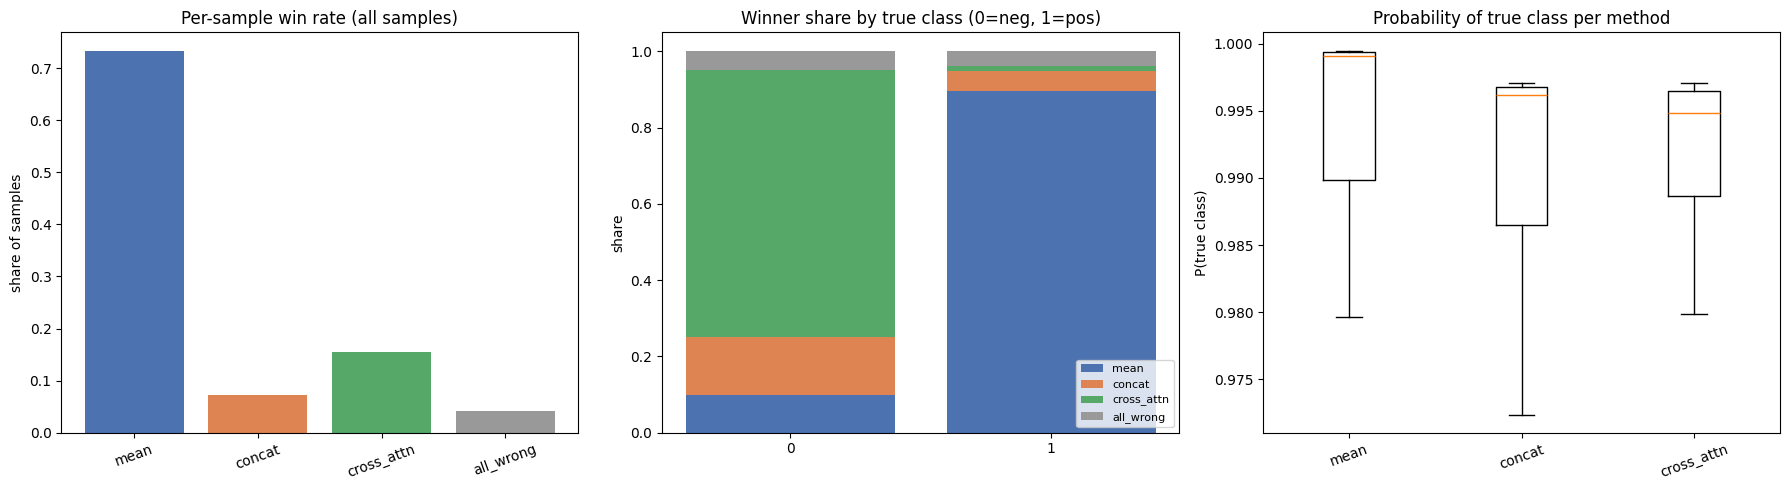

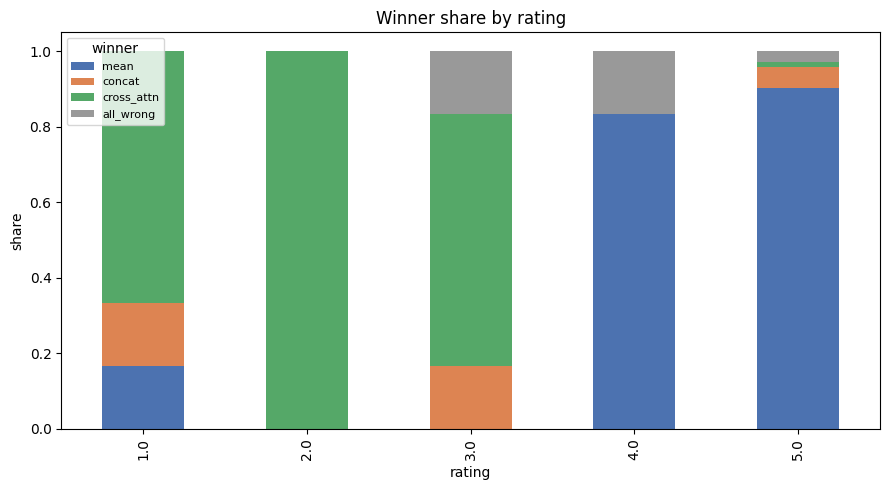

In [ ]:
# ---- Visualizations ----
methods_order = FUSION_METHODS + ["all_wrong"]
palette = {"mean": "#4C72B0", "concat": "#DD8452", "cross_attn": "#55A868", "all_wrong": "#999999"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Overall win rate per method
win_counts = df["winner"].value_counts().reindex(methods_order, fill_value=0)
axes[0].bar(win_counts.index, win_counts.values / len(df),
            color=[palette[m] for m in win_counts.index])
axes[0].set_title("Per-sample win rate (all samples)")
axes[0].set_ylabel("share of samples")
axes[0].tick_params(axis="x", rotation=20)

# 2) Win rate by true class
ct = pd.crosstab(df["label"], df["winner"]).reindex(columns=methods_order, fill_value=0)
ct_norm = ct.div(ct.sum(axis=1), axis=0)
bottom = np.zeros(len(ct_norm))
for m in methods_order:
    axes[1].bar(ct_norm.index.astype(str), ct_norm[m].values, bottom=bottom, label=m, color=palette[m])
    bottom += ct_norm[m].values
axes[1].set_title("Winner share by true class (0=neg, 1=pos)")
axes[1].set_ylabel("share")
axes[1].legend(fontsize=8)

# 3) Distribution of true-class probability per method
data = [df[f"{m}_prob_true"].values for m in FUSION_METHODS]
axes[2].boxplot(data, labels=FUSION_METHODS, showfliers=False)
axes[2].set_title("Probability of true class per method")
axes[2].set_ylabel("P(true class)")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

# Stacked winner share by rating
ct_rating = pd.crosstab(df["rating"], df["winner"]).reindex(columns=methods_order, fill_value=0)
ct_rating_norm = ct_rating.div(ct_rating.sum(axis=1), axis=0)
ax = ct_rating_norm.plot(kind="bar", stacked=True, figsize=(9, 5),
                         color=[palette[m] for m in methods_order])
ax.set_title("Winner share by rating")
ax.set_ylabel("share")
ax.legend(title="winner", fontsize=8)
plt.tight_layout()
plt.show()
